<h3><center>Introduction to Building a Quant Pricing Library</center></h3>
<h1><center>Volatility Surface, Numerical Greeks</center></h1>
<h3><center>Tamas Glatz</h3>
<h3><center>(Based on Gabor Friedmann's Lecutre Notes)</center></h3>
<h4><center>14 October, 2026</center></h4>


### <b> The law of supply and demand:</b>
* Number of people who buy go $ \uparrow $, or sell go $ \downarrow $ $\Longrightarrow $ Price goes $\uparrow$
* Number of people who buy go $ \downarrow $, or sell go $ \uparrow $ $\Longrightarrow $ Price goes $\downarrow $
* This simple dynamic drives the price of many goods... For example
    * Market price of face masks during covid
    * <b> Market price of options<b> (quotes)

## <b>Goal of option pricing:</b>
* Come up with a model that is able to re-price "frequently traded" (liquid) products
* Use the model to understand how to eliminate risks (hedging)
* Use the model to price other, "non-frequently traded" (illiquid) products

# Moneyness

Measures whether the option would make money if it were exercised immediately. We define moneyness as current spot price divided by strike price:
$$ M = \dfrac{S_t}{K} $$

At $M = 1$, the option is called at-the-money (ATM). Otherwise, the option is called either in-the-money (ITM) or out-of-the-money (OTM).

<img src="./img/moneyness.jpg" style="margin-left:auto; margin-right:auto; width: 1000px;" />

## What did we learn?

Black-Scholes model assumptions:
* Underlying asset price follows GBM:

$$ dS_{t}=\mu S_{t}\,dt+\sigma S_{t}\,dW_{t} $$
* Underlying asset price has <b>known and constant</b> volatility ($\sigma$)
* Log returns of the underlying asset are normally distributed

### Under these assumptions we can derive the price of a European Call option $c_0$ (by ruling out arbitrage):

$$
c_0 = S_0 N(d_1) - K e^{-rT} N(d_2)
$$
where
$$
d_1 = \frac{\ln\left(\frac{S_0}{K}\right) + \left(r + \frac{\sigma^2}{2}\right)T}{\sigma\sqrt{T}}; \, d_2 = d_1 - \sigma\sqrt{T}
$$
So essentially $c_0$ is a function of 5 parameters (bijection pour la volatilité):
$$
c_0 = f_{BS}\left(S_0, K, T, r, {\sigma}\right)
$$
le risk-free interest rate est une variable aléatoire dans la vraie vie
#### Which of these parameters are known to us?

#### Remember, our goal with the model is NOT to determine how much the option we observe should cost, but to know how to hedge it.

$$ \color{red}{\sigma} = f^{-1}_{BS}\left(S_0, K, T, r, c_0\right) $$

<b>Implied volatility</b>: The volatility obtained from market quotes using Black-Scholes formula. It represents what the market is implying the volatility will be in the future based on option prices.

#### Based on BS assumptions, implied volatility should be constant for all options on a given underlying. Is that true?
Non, donc il y a quelque chose que BS ne capture pas

<img src="./img/implied_vol_smile.jpg" style="margin-left:auto; margin-right:auto; width: 1500px;" />

<img src="./img/smile_skew.jpg" style="margin-left:auto; margin-right:auto; width: 1500px;" alt="Source: https://analystprep.com/study-notes/frm/part-2/market-risk-measurement-and-management/volatility-smiles/" />

## Why?

Highligting just one concept: Protective Put Option Strategy

There is high demand for put options with low strike as they serve as a protection against huge losses.

<img src="./img/protective_put.jpg" style="margin-left:auto; margin-right:auto; width: 400px;" />


<img src="./img/implied_vol_termskew.jpg" style="margin-left:auto; margin-right:auto; width: 1500px;" />

<b>Conclusion</b>: The volatility in our model should depend on strike and expiry: <b>$ \sigma = \sigma(K,T) $<b>

Using market quotes, we can derive an <b>implied volatility grid</b>. Applying some interpolation technique between grid points we can build an <b>implied volatility surface</b>.

Let's look at some examples!

BlueChip Bank, TipTop Solutions, Money Mall


In [30]:
# Add current folder and QuantCourseBP folder to syspath to import modules
import sys
import numpy as np
from pathlib import Path
current = Path(Path().resolve())
sys.path.append(str(current))
sys.path.append(str(current.parents[2]))

from src.utils import *
from src.market_data import *

# Make charts interactive - remove this line if charts throws error
%matplotlib widget

# Initialize market data
MarketData.initialize()

In [31]:
underlying = Stock.BLUECHIP_BANK
volgrid = MarketData.get_volgrid()[underlying]

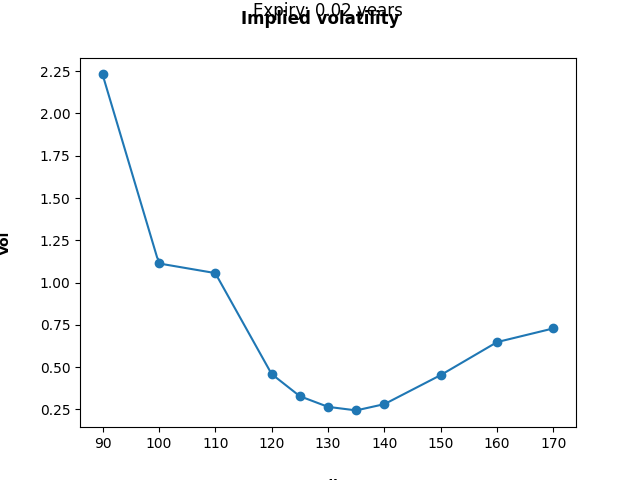

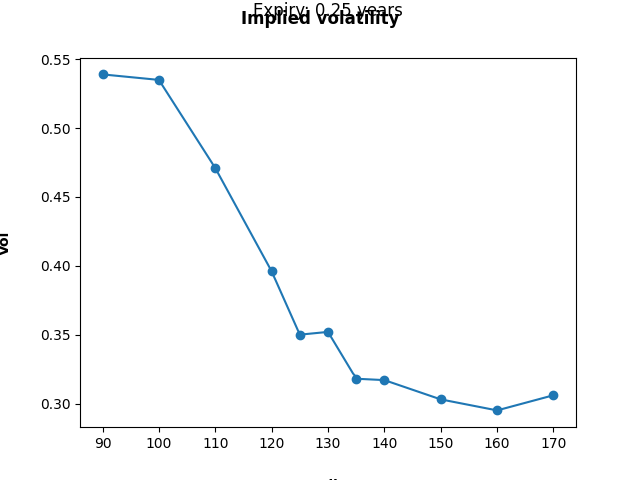

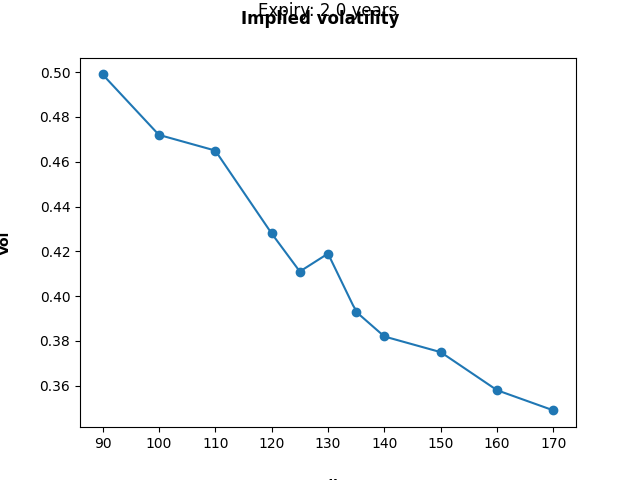

In [32]:
flag = True
plot_vol_slice(volgrid, expiry=0.02, linear_interpolation=flag) # 7D
plot_vol_slice(volgrid, expiry=0.25, linear_interpolation=flag) # 3M
plot_vol_slice(volgrid, expiry=2.00, linear_interpolation=flag) # 2Y

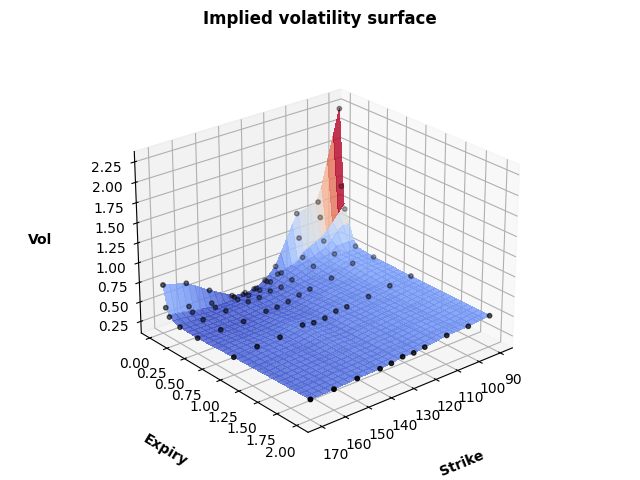

In [33]:
plot_vol_surface(volgrid)

## What changes?

Underlying asset price diffusion:
$$ \; dS_{t}=\mu S_{t}\,dt+\sigma S_{t}\,dW_{t} $$


$$ \; dS_{t}=\mu S_{t}\,dt+\color{red}{\sigma(K,T)} S_{t}\,dW_{t} $$

We can determine $ \sigma(K,T) $ based on the contract we want to price, then use that constant within the Black-Scholes framework. Let's call this extension of BS model as <b>flat volatility model</b>.

Volatility market data is no longer a single number, but a tabular data (grid) for each underlying, hence we outsource them to csv files for maintainability.

<br>
<br>

Let's do coding!

# Tasks

## MarketData - market_data.py

* Understand the new structure of MarketData class
* Understand how VolGrid class works

## MarketModel - model.py

* Implement BSVol and FlatVol models in the pricing library

## Jupyter notebook

* Price a few contracts using both Black-Scholes and FlatVol models

In [34]:
# Add current folder and QuantCourseBP folder to syspath to import modules
import sys
from pathlib import Path
current = Path(Path().resolve())
sys.path.append(str(current))

for p in [str(current.parents[2]),str(current.parents[2]/"src") ]:
    if p in sys.path:
        sys.path.remove(p)

from market_data import MarketData
from pricer import *
from model import *

In [35]:
MarketData.initialize()

In [36]:
und = Stock.BLUECHIP_BANK
put_call = PutCallFwd.CALL
ls = LongShort.LONG
MarketData.get_volgrid()

{<Stock.TEST_COMPANY: 'TEST_COMPANY'>: <market_data.VolGrid at 0x26bb6608f50>,
 <Stock.BLUECHIP_BANK: 'BLUECHIP_BANK'>: <market_data.VolGrid at 0x26bb6609490>,
 <Stock.TIPTOP_SOLUTIONS: 'TIPTOP_SOLUTIONS'>: <market_data.VolGrid at 0x26bb660b2c0>,
 <Stock.MONEY_MALL: 'MONEY_MALL'>: <market_data.VolGrid at 0x26bb660b560>}

In [37]:
und = Stock.BLUECHIP_BANK
put_call = PutCallFwd.CALL
ls = LongShort.LONG
strike = 1.0 * MarketData.get_spot()[und] # at-the-money strike i.e. strike = spot price
strike_itm = strike * 1.1
strike_otm = strike * 0.9
exp = 1

forward = ForwardContract(und, ls, strike, exp)
option = EuropeanContract(und, put_call, ls, strike , exp)
option_itm = EuropeanContract(und, put_call, ls, strike_itm, exp)
option_otm = EuropeanContract(und, put_call, ls, strike_otm, exp)

print(option)

{'underlying': <Stock.BLUECHIP_BANK: 'BLUECHIP_BANK'>, 'type': <PutCallFwd.CALL: 'CALL'>, 'long_short': <LongShort.LONG: 'LONG'>, 'strike': np.float64(130.17), 'expiry': 1}


In [38]:
call_pricer_black_scholes = EuropeanAnalyticPricer(option, BSVolModel(und), None)
call_pricer_black_scholes.calc_fair_value()

np.float64(22.51566312744199)

In [39]:
call_pricer_flat_vol = EuropeanAnalyticPricer(option, FlatVolModel(und), None)
call_pricer_flat_vol_itm = EuropeanAnalyticPricer(option_itm, FlatVolModel(und), None)
call_pricer_flat_vol_otm = EuropeanAnalyticPricer(option_otm, FlatVolModel(und), None)
call_pricer_flat_vol_itm.calc_fair_value()

np.float64(17.50580599019625)

# Greeks

* Understanding the sensitivities of a porfolio is crutial to eliminate them (hedging)
* So far we had analytical formulas to calculate greeks, usually this is not the case
* In most cases we calculate greeks numerically using finite difference approximation (forward, backward, central)

## Finite difference approximation (central, absolute)
$$ f'(x)\approx\dfrac{f(x+\Delta)-f(x-\Delta)}{2\Delta} $$

$$ f''(x)\approx\dfrac{f'(x+\dfrac{\Delta}{2})-f'(x-\dfrac{\Delta}{2})}{\Delta}\approx\dfrac{f(x+\Delta)-2f(x)+f(x-\Delta)}{\Delta^2} $$

# Tasks

## Pricer - pricer.py

* Implement calc_delta() function using finite difference approximation.
* Compare the results of analytic and numerical formulas for delta and gamma.

In [40]:
#Calculation of the delta analytically and with finite difference method (central, with relative bump size type), and calculation of the absolute error.
Pricer.finite_difference_method = FiniteDifferenceMethod.CENTRAL
Pricer.bump_size_type = BumpSizeType.RELATIVE
Pricer.bump_size = 0.01

call_european_pricer = EuropeanAnalyticPricer(option, FlatVolModel(und), None)
delta_analytic_european = call_european_pricer.calc_delta(GreekMethod.ANALYTIC)

delta_bump_european = call_european_pricer.calc_delta(GreekMethod.BUMP)

print("Delta analytic European:", delta_analytic_european)
print("Delta numerical :", delta_bump_european)
print("Absolute error :", abs(delta_analytic_european - delta_bump_european))

Delta analytic European: 0.6261627301230436
Delta numerical : 0.6261321494852531
Absolute error : 3.058063779048936e-05


In [41]:
#Same for the gamma. 
Pricer.finite_difference_method = FiniteDifferenceMethod.CENTRAL
Pricer.bump_size_type = BumpSizeType.RELATIVE
Pricer.bump_size = 0.01

call_european_pricer = EuropeanAnalyticPricer(option, FlatVolModel(und), None)
gamma_analytic_european = call_european_pricer.calc_gamma(GreekMethod.ANALYTIC)

gamma_bump_european = call_european_pricer.calc_gamma(GreekMethod.BUMP)

print("Gamma analytic European:", gamma_analytic_european)
print("Gamma numerical :", gamma_bump_european)
print("Absolute error :", abs(gamma_analytic_european - gamma_bump_european))

Gamma analytic European: 0.007641774960675401
Gamma numerical : 0.007641670021721092
Absolute error : 1.0493895430917222e-07


# Assignments - Numerical greeks

1. Introduce two class variables in Pricer that store the finite difference method (forward, backward, central) to be used in numerical greek calculation, and whether the bump size is absolute or relative. Create two Enums to store the labels. Implement all combinations for delta and gamma calculation.<br>Compare greeks using the analytic and the finite difference approximation on a set of European options and visualize the numerical error. Compare absolute and relative bumping and suggest optimal bump sizes. **(15 points)**

In [42]:
#General way of calculation of the absolute errors of gamma and delta between analytical and with finite difference method, for all the combinations of
#bump sizes, bump size types, finite difference methods, options itm/atm/otm. Doesn't answer to a question of the assignment.  

bump_sizes = [10.0**(-i) for i in range(1, 8)]

bump_types = [BumpSizeType.ABSOLUTE, BumpSizeType.RELATIVE]

diff_methods = [FiniteDifferenceMethod.CENTRAL, FiniteDifferenceMethod.FORWARD, FiniteDifferenceMethod.BACKWARD]

option_pricers = {"Call ATM": call_pricer_flat_vol, "Call ITM": call_pricer_flat_vol_itm, "Call OTM": call_pricer_flat_vol_otm}

results =[]

for option_name, pricer in option_pricers.items():
    for bump_type in bump_types:
        Pricer.bump_size_type = bump_type
        for diff_method in diff_methods:
            Pricer.finite_difference_method = diff_method
            for bump_size in bump_sizes:
                Pricer.bump_size = bump_size
                delta_bump = pricer.calc_delta(GreekMethod.BUMP)
                delta_analytic = pricer.calc_delta(GreekMethod.ANALYTIC)
                gamma_bump = pricer.calc_gamma(GreekMethod.BUMP)
                gamma_analytic = pricer.calc_gamma(GreekMethod.ANALYTIC)

                results.append({"option": option_name, "bump type": bump_type.value, "bump size": bump_size, "finite difference method": 
                                diff_method.value, "delta error": abs(delta_bump - delta_analytic), "gamma error": abs(gamma_bump - gamma_analytic)})

#for result in results:
    #print(result)


In [43]:
#Plotter of the previous homeworks. 

import matplotlib.pyplot as plt
from matplotlib import rcParams # detailed parameter setting
""" more details on customization: https://matplotlib.org/stable/tutorials/introductory/customizing.html """
from typing import Dict, List, Union


# some type hints in the header of the function
def my_plotter(x: List[float], y: Union[List[float], List[List[float]]], layout: Dict = {}, names: List[str] = None) -> None:
    """ inline for loop is called 'list comprehension' """
    y = [y] if all(isinstance(item, float) for item in y) else y
    
    plt.figure(figsize=(8, 4))
    lines = []
    show_legend = True if names is not None else False
    # show_legend = True if names else False  -> here is fine, but be cautious bc 0, empty str and empty list will be evaulated to False

    """ setup some basic key-word arguments for plot line """
    plot_kwargs = {
        'linestyle': 'solid',
        'linewidth': 4
    }
    if names is not None:
        show_legend = True
        if len(names) != len(y):
            raise ValueError("Length of names is not matching with number of plotted y lists.")

    """ 'enumerate' add a counter to the loop """
    for i, y_item in enumerate(y):
        if show_legend:
            plot_kwargs['label'] = names[i]
        _line = plt.plot(x, y_item, **plot_kwargs)
        lines.append(_line)

    if show_legend:
        plt.legend(fontsize=16)
    if 'title' in layout:
        plt.title(layout['title'], fontsize=20)
        rcParams['axes.titlepad'] = 30 # moving the title a little further away from the plot
    if 'x_label' in layout:
        plt.xlabel(layout['x_label'], fontsize=16)
        rcParams['axes.labelpad'] = 20 # moving the ax label a little further away from the plot

    """ enhance axes """
    ax = plt.gca() # gca: get current axes
    ax.axhline(linestyle='--', color='black', linewidth=1)
    plt.xscale("log")
    plt.yscale("log")
    plt.show()


In [44]:
#Comparison of the methods to calculate delta and gamma (finite difference method and analytical) for different European options and different 
#bump size types and finite difference methods. 

Pricer.bump_size = 0.01
#Pricer.bump_size = 0.000001

bump_types = [BumpSizeType.ABSOLUTE, BumpSizeType.RELATIVE]

diff_methods = [FiniteDifferenceMethod.CENTRAL, FiniteDifferenceMethod.FORWARD, FiniteDifferenceMethod.BACKWARD]

#The call pricers and the strike_itm and strike_otm are defined above. 
option_pricers = {"Call ATM": call_pricer_flat_vol, "Call ITM": call_pricer_flat_vol_itm, "Call OTM": call_pricer_flat_vol_otm}

results =[]

for diff_method in diff_methods:
    Pricer.finite_difference_method = diff_method
    for bump_type in bump_types:
        Pricer.bump_size_type = bump_type
        for option_name, pricer in option_pricers.items():
            delta_bump = pricer.calc_delta(GreekMethod.BUMP)
            delta_analytic = pricer.calc_delta(GreekMethod.ANALYTIC)
            gamma_bump = pricer.calc_gamma(GreekMethod.BUMP)
            gamma_analytic = pricer.calc_gamma(GreekMethod.ANALYTIC)

            results.append({"option": option_name, "delta error": abs(delta_bump - delta_analytic), "gamma error": abs(gamma_bump - gamma_analytic)})
        print("Delta and gamma error for bump type ", bump_type.value, " and finite difference method ", diff_method.value)
        for result in results:
            print(result)
        print('')
        results = []

#The finite difference method tend to be more precise for relative bump size type when the bump size is small and for absolute bump size type when 
#the bump size is not too small. It is globally the case for all finite difference methods and all options. 

Delta and gamma error for bump type  ABSOLUTE  and finite difference method  CENTRAL
{'option': 'Call ATM', 'delta error': np.float64(1.8057181305763947e-09), 'gamma error': np.float64(1.808893208832263e-10)}
{'option': 'Call ITM', 'delta error': np.float64(1.2121093018180318e-09), 'gamma error': np.float64(7.274873065066245e-11)}
{'option': 'Call OTM', 'delta error': np.float64(1.824084883139676e-09), 'gamma error': np.float64(5.299035949618558e-11)}

Delta and gamma error for bump type  RELATIVE  and finite difference method  CENTRAL
{'option': 'Call ATM', 'delta error': np.float64(3.058063779048936e-05), 'gamma error': np.float64(1.0493895430917222e-07)}
{'option': 'Call ITM', 'delta error': np.float64(2.0537439803902657e-05), 'gamma error': np.float64(2.695007000150934e-07)}
{'option': 'Call OTM', 'delta error': np.float64(3.088654320815287e-05), 'gamma error': np.float64(1.213615637690041e-07)}

Delta and gamma error for bump type  ABSOLUTE  and finite difference method  FORWARD
{

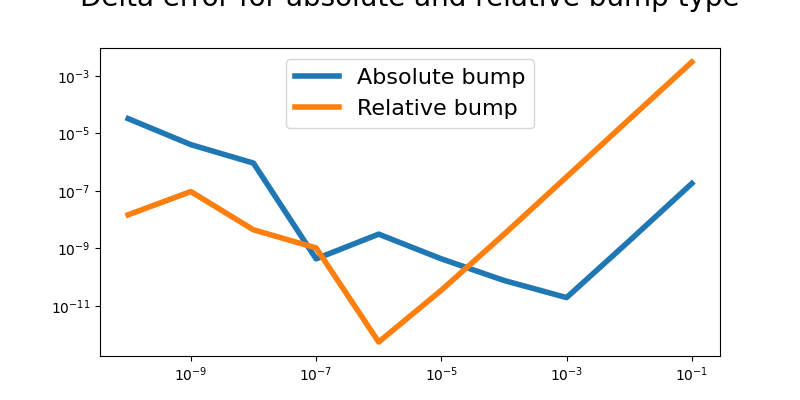

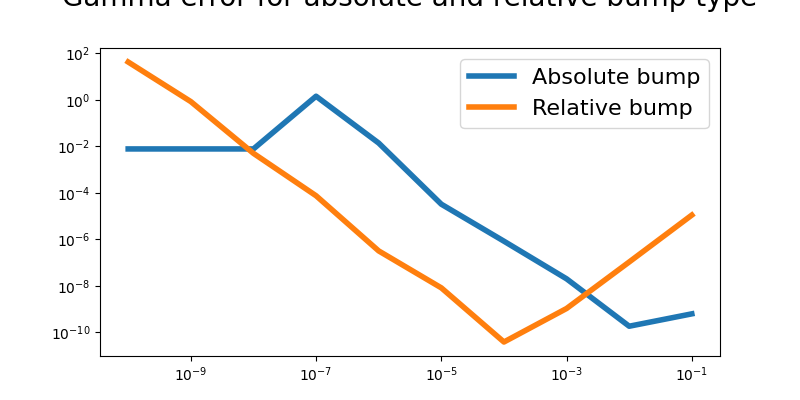

In [45]:
#Calculation of the absolute error for central finite difference method and atm option. We let the bump size and the bump size type vary. 

bump_sizes = [10.0**(-i) for i in range(1, 11)]

bump_types = [BumpSizeType.ABSOLUTE, BumpSizeType.RELATIVE]

diff_method = FiniteDifferenceMethod.CENTRAL
Pricer.finite_difference_method = diff_method
pricer = call_pricer_flat_vol

results_absolute = []
results_relative = []

for bump_type in bump_types:
    Pricer.bump_size_type = bump_type
    for bump_size in bump_sizes:
        Pricer.bump_size = bump_size
        delta_bump = pricer.calc_delta(GreekMethod.BUMP)
        delta_analytic = pricer.calc_delta(GreekMethod.ANALYTIC)
        gamma_bump = pricer.calc_gamma(GreekMethod.BUMP)
        gamma_analytic = pricer.calc_gamma(GreekMethod.ANALYTIC)

        result = {"bump size": bump_size, "delta error": abs(delta_bump - delta_analytic), "gamma error": abs(gamma_bump - gamma_analytic)}

        if bump_type == BumpSizeType.ABSOLUTE:
            results_absolute.append(result)
        else:
            results_relative.append(result)

absolute_delta_errors = [r["delta error"] for r in results_absolute]
relative_delta_errors = [r["delta error"] for r in results_relative]

layout_delta = {"title": "Delta error for absolute and relative bump type", "x_label": "Bump size", "y_label": "Delta error"}
my_plotter(bump_sizes, [absolute_delta_errors, relative_delta_errors], layout = layout_delta, names=["Absolute bump", "Relative bump"])

absolute_gamma_errors = [r["gamma error"] for r in results_absolute]
relative_gamma_errors = [r["gamma error"] for r in results_relative]

layout_gamma = {"title": "Gamma error for absolute and relative bump type", "x_label": "Bump size", "y_label": "Gamma error"}
my_plotter(bump_sizes, [absolute_gamma_errors, relative_gamma_errors], layout = layout_gamma, names=["Absolute bump", "Relative bump"])

#For Delta greek and absolute bump size type, we have the optimal bump size at 10^(-3). 
#For Delta greek and relative bump size type, we have the optimal bump size at 10^(-6).
#For Gamma greek and absolute bump size type, we have the optimal bump size at 10^(-2). 
#For Gamma greek and relative bump size type, we have the optimal bump size at 10^(-4). 